# Activated sludge: BSM1 at steady state, differentiated (`difflow_water.wastewater`)

The Benchmark Simulation Model no. 1 (BSM1; Alex et al. 2008) is the standard municipal activated-sludge plant: two anoxic and three aerobic ASM1 reactors (6000 m3), an internal nitrate recycle, a 10-layer Takacs secondary settler and a sludge recycle, treating 18,446 m3/d. `activated_sludge_plant` solves it at steady state as one equation set (200 days of stiff dynamics, then Newton), so every output has exact gradients by implicit differentiation.

1. The open-loop steady state, against the BSM1 report's Tables 6-7.
2. Sensitivities of effluent nitrogen and energy to aeration and recycle.
3. Minimum aeration + pumping energy subject to BSM1's effluent limits (steady state, constant influent).

In [1]:
import time
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from difflow_water.wastewater import (STATES, ActivatedSludgeParams, BSM1_LIMITS,
                                      activated_sludge_plant, bsm1_indices, bsm1_influent)

infl = bsm1_influent()
t = time.time()
r = activated_sludge_plant(infl)
print(f"converged {bool(r['converged'])} in {time.time() - t:.1f} s; sludge age {float(r['sludge_age']):.2f} d")
report5 = {"S_S": 0.889, "X_BH": 2559, "X_BA": 150, "S_O": 0.491, "S_NO": 10.4, "S_NH": 1.73, "S_ALK": 4.13}
for s, v in report5.items():
    print(f"reactor 5 {s:6s} BSM1 report {v:8.4g}   difflow {float(r['reactors'][4][STATES.index(s)]):8.4g}")

converged True in 15.9 s; sludge age 9.14 d
reactor 5 S_S    BSM1 report    0.889   difflow   0.8895
reactor 5 X_BH   BSM1 report     2559   difflow     2559
reactor 5 X_BA   BSM1 report      150   difflow    149.8
reactor 5 S_O    BSM1 report    0.491   difflow   0.4909
reactor 5 S_NO   BSM1 report     10.4   difflow    10.42
reactor 5 S_NH   BSM1 report     1.73   difflow    1.733
reactor 5 S_ALK  BSM1 report     4.13   difflow    4.126


{'COD': 47.55, 'BOD5': 2.65, 'TSS': 12.5, 'N_Kj': 3.63, 'N_tot': 14.05, 'S_NH': 1.73, 'S_NO': 10.42, 'EQ': 5254.28, 'AE': 3341.39, 'PE': 388.17}


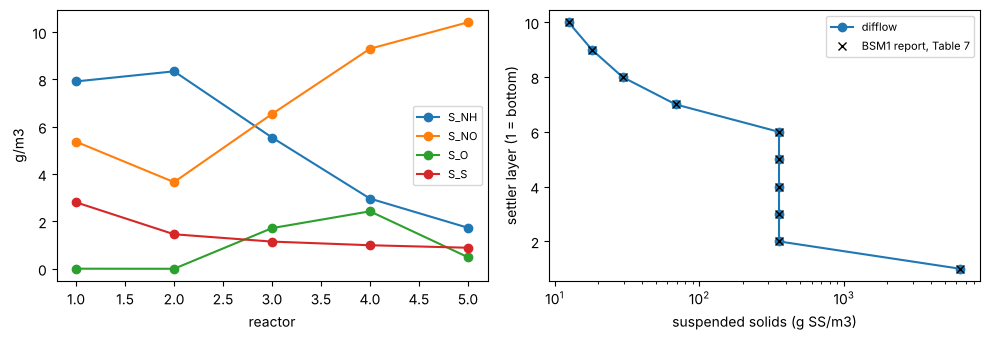

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
k = np.arange(1, 6)
for s in ["S_NH", "S_NO", "S_O", "S_S"]:
    ax[0].plot(k, np.asarray(r["reactors"][:, STATES.index(s)]), "o-", label=s)
ax[0].set_xlabel("reactor"); ax[0].set_ylabel("g/m3"); ax[0].legend(fontsize=8)
report7 = [6394, 356, 356, 356, 356, 356, 69.0, 29.5, 18.1, 12.5]
ax[1].semilogx(np.asarray(r["settler_solids"]), np.arange(1, 11), "o-", label="difflow")
ax[1].semilogx(report7, np.arange(1, 11), "kx", label="BSM1 report, Table 7")
ax[1].set_xlabel("suspended solids (g SS/m3)"); ax[1].set_ylabel("settler layer (1 = bottom)"); ax[1].legend(fontsize=8)
fig.tight_layout()
idx = bsm1_indices(r)
print({k: round(float(v), 2) for k, v in idx.items() if k != "violations"})

## Sensitivities

The design and operating handles: oxygen transfer in the three aerobic reactors (KLa, 1/d) and the internal recycle Q_a (m3/d). One forward-mode Jacobian of the steady state. The 200 days of dynamics that find the steady state are not differentiated; the steady state is, by the implicit-function theorem at the Newton solution.

In [3]:
def outputs(x):
    p = ActivatedSludgeParams(KLa=(0.0, 0.0, x[0], x[1], x[2]), Q_a=x[3])
    i = bsm1_indices(activated_sludge_plant(infl, p), p)
    return jnp.stack([i["S_NH"], i["S_NO"], i["N_tot"], i["EQ"], i["AE"] + i["PE"]])

x0 = jnp.array([240.0, 240.0, 84.0, 55338.0])
t = time.time()
J = jax.jit(jax.jacfwd(outputs))(x0)
print(f"Jacobian in {time.time() - t:.0f} s (includes compilation)")
rows = ["S_NH,e (g N/m3)", "S_NO,e (g N/m3)", "N_tot,e (g N/m3)", "EQ (kg PU/d)", "AE + PE (kWh/d)"]
cols = ["KLa3", "KLa4", "KLa5", "Q_a"]
print(f"{'':20s}" + "".join(f"{c:>14s}" for c in cols))
for n, row in zip(rows, np.asarray(J)):
    print(f"{n:20s}" + "".join(f"{v:14.3e}" for v in row))

Jacobian in 19 s (includes compilation)
                              KLa3          KLa4          KLa5           Q_a
S_NH,e (g N/m3)         -1.300e-02    -1.177e-02    -4.218e-02     6.978e-06
S_NO,e (g N/m3)          2.643e-02     2.458e-02     9.371e-02     6.149e-06
N_tot,e (g N/m3)         1.339e-02     1.281e-02     5.163e-02     1.390e-05
EQ (kg PU/d)            -2.299e+00    -1.942e+00    -5.893e+00     5.341e-03
AE + PE (kWh/d)          5.924e+00     5.924e+00     5.924e+00     4.000e-03


Aerating more lowers ammonia but raises nitrate by more (more nitrification, and more oxygen carried back to the anoxic zone in the internal recycle), so total nitrogen rises. At the open-loop recycle (55,338 m3/d, three times the influent) more internal recycle raises total nitrogen slightly: the anoxic zone is already short of readily biodegradable substrate, and the extra oxygen recycled with the nitrate costs more denitrification than the extra nitrate gains.

## Minimum energy within the effluent limits

Minimize aeration + pumping energy over KLa3-5 and Q_a, subject to BSM1's effluent limits (Table 9: total N < 18, ammonia < 4 g N/m3; COD, BOD5 and TSS are far inside their limits here) at steady state. KLa is bounded by 360 1/d (15 1/h), Q_a by 5 Q_0. Steady state with constant influent is a design calculation, not BSM1's dynamic evaluation.

In [4]:
from scipy.optimize import minimize

def energy(x):
    p = ActivatedSludgeParams(KLa=(0.0, 0.0, x[0], x[1], x[2]), Q_a=x[3])
    i = bsm1_indices(activated_sludge_plant(infl, p), p)
    return (i["AE"] + i["PE"]) / 1000.0

def margins(x):
    p = ActivatedSludgeParams(KLa=(0.0, 0.0, x[0], x[1], x[2]), Q_a=x[3])
    i = bsm1_indices(activated_sludge_plant(infl, p), p)
    return -jnp.stack([i["violations"]["N_tot"], i["violations"]["S_NH"]])

f, g = jax.jit(energy), jax.jit(jax.grad(energy))
c, cj = jax.jit(margins), jax.jit(jax.jacfwd(margins))
scale = np.array([100.0, 100.0, 100.0, 1e4])
t = time.time()
res = minimize(lambda y: float(f(y * scale)), np.asarray(x0) / scale,
               jac=lambda y: np.asarray(g(y * scale)) * scale, method="SLSQP",
               bounds=[(0.0, 3.6), (0.0, 3.6), (0.0, 3.6), (0.0, 9.223)],
               constraints=[{"type": "ineq", "fun": lambda y: np.asarray(c(y * scale)),
                             "jac": lambda y: np.asarray(cj(y * scale)) * scale}],
               options={"maxiter": 60, "ftol": 1e-9})
xs = res.x * scale
print(res.message, f"({res.nit} iterations, {time.time() - t:.0f} s)")
print(f"KLa3-5 = {xs[0]:.0f}, {xs[1]:.0f}, {xs[2]:.0f} 1/d; Q_a = {xs[3]:.0f} m3/d")
print(f"energy {float(f(xs)) * 1000:.0f} kWh/d (open loop {float(f(x0)) * 1000:.0f}); limit margins (g N/m3) {np.round(np.asarray(c(xs)), 4)}")

Optimization terminated successfully (16 iterations, 78 s)
KLa3-5 = 172, 157, 141 1/d; Q_a = 18820 m3/d


energy 3025 kWh/d (open loop 3730); limit margins (g N/m3) [ 2.1377 -0.    ]


At the optimum the ammonia limit binds (4 g N/m3) and total nitrogen has margin to spare: aeration is cut as far as nitrification allows, and the internal recycle comes down because pumping costs energy and, at this point, buys no nitrogen removal.

## What this is and is not

- The plant model is BSM1 as its report states it, and it reproduces the report's open-loop steady state to its printed digits (and WaterTAP's BSM1 example to 1e-7; `benchmarks/watertap/compare_bsm1.py`).
- The optimization is at steady state with the constant (average dry-weather) influent. BSM1 proper evaluates control strategies dynamically over its dry, rain and storm influent files, which are not reproduced here.
- The aeration energy formula is BSM1's (Degremont DP230 diffusers at 4 m), a benchmark convention.